<a href="https://colab.research.google.com/github/sanchit-cmd/Titanic-Survival/blob/main/Titanic_Competition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
import os

# Download latest version of the Titanic competition
path = kagglehub.competition_download('titanic')

print("Path to competition files:", path)

Path to competition files: /root/.cache/kagglehub/competitions/titanic


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv(path + '/train.csv')
test_df = pd.read_csv(path + '/test.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
df.set_index("PassengerId", inplace=True)
df.drop(["Name", "Ticket", "Cabin"], axis=1, inplace=True)
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
PassengerId,,,,,,,,
1,0,3,male,22.0,1,0,7.2500,S
2,1,1,female,38.0,1,0,71.2833,C
3,1,3,female,26.0,0,0,7.9250,S
4,1,1,female,35.0,1,0,53.1000,S
5,0,3,male,35.0,0,0,8.0500,S


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 62.6+ KB


In [ ]:
df.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
df['Age'] = df['Age'].fillna(df['Age'].mean())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

df['Age'] = df['Age'].astype(int)
df.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Embarked,0


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,8))

<Figure size 1200x800 with 0 Axes>

<Figure size 1200x800 with 0 Axes>

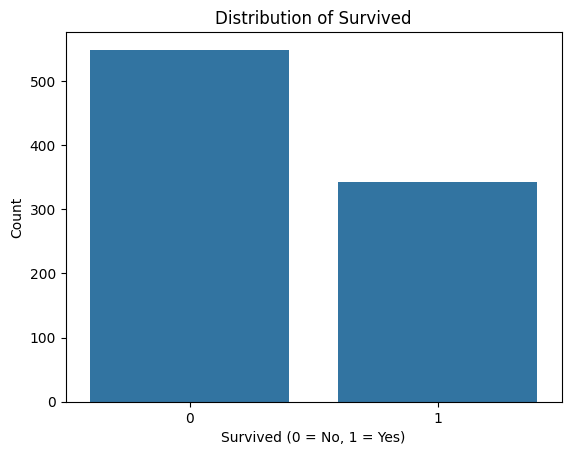

In [ ]:
sns.countplot(x='Survived', data=df)
plt.title('Distribution of Survived')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

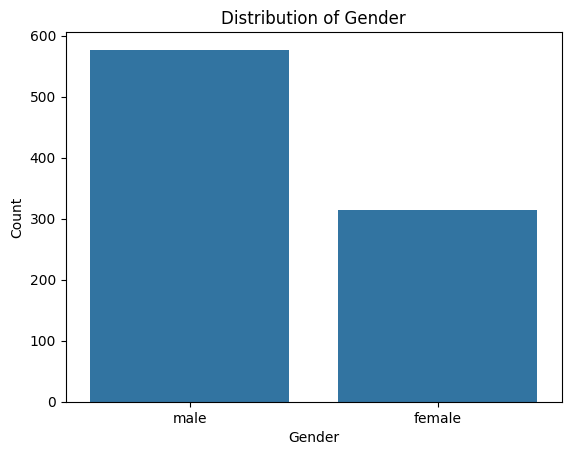

In [ ]:
sns.countplot(x='Sex', data=df)
plt.title('Distribution of Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

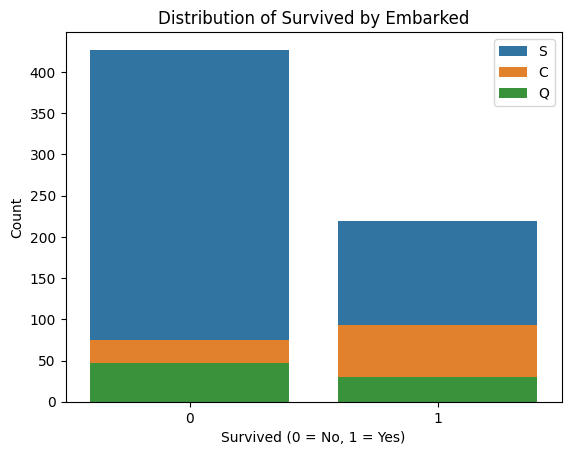

In [ ]:
for embarked in df['Embarked'].unique():
    sns.countplot(x='Survived', data=df[df['Embarked'] == embarked], label=embarked)
plt.title('Distribution of Survived by Embarked')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.legend()
plt.show()

In [ ]:
for embarked in df['Embarked'].dropna().unique():
    mean_fare = df[df['Embarked'] == embarked]['Fare'].mean()
    print(f"Embarked: {embarked} -> Mean Fare (Price): {mean_fare:.2f}")

Embarked: S -> Mean Fare (Price): 27.24
Embarked: C -> Mean Fare (Price): 59.95
Embarked: Q -> Mean Fare (Price): 13.28


In [ ]:
for cls in df['Pclass'].unique():
    mean_fare = df[df['Pclass'] == cls]['Fare'].mean()
    print(f"Class: {cls} -> Mean Fare (Price): {mean_fare:.2f}")

    survivor_count = df[(df['Pclass'] == cls) & (df['Survived'] == 1)].shape[0]
    print(f"Class: {cls} -> Survivor Count: {survivor_count}")

    death_count = df[(df['Pclass'] == cls) & (df['Survived'] == 0)].shape[0]
    print(f"Class: {cls} -> Death Count: {death_count}")

    print()


Class: 3 -> Mean Fare (Price): 13.68
Class: 3 -> Survivor Count: 119
Class: 3 -> Death Count: 372

Class: 1 -> Mean Fare (Price): 84.15
Class: 1 -> Survivor Count: 136
Class: 1 -> Death Count: 80

Class: 2 -> Mean Fare (Price): 20.66
Class: 2 -> Survivor Count: 87
Class: 2 -> Death Count: 97



In [ ]:
df_encoded = pd.get_dummies(df, columns=['Sex', 'Embarked'], drop_first=True, dtype=int)
df_encoded.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
PassengerId,,,,,,,,,,,
1,0,3,22,1,0,7.2500,0,1,0,0,1
2,1,1,38,1,0,71.2833,1,0,1,0,0
3,1,3,26,0,0,7.9250,1,0,0,0,1
4,1,1,35,1,0,53.1000,1,0,0,0,1
5,0,3,35,0,0,8.0500,0,1,0,0,1


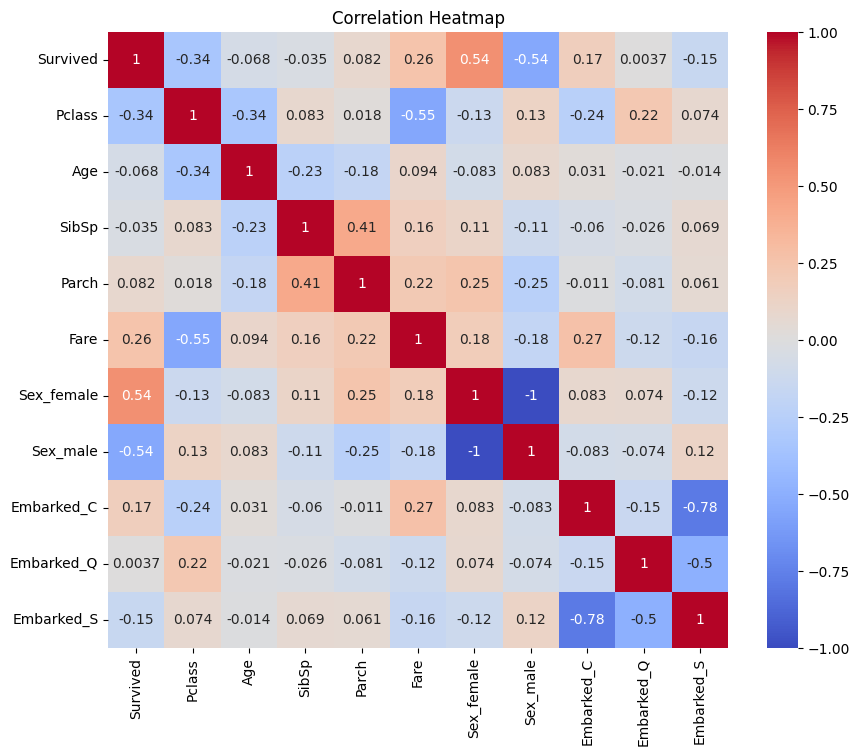

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_encoded.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
test_df.drop(["Name", "Ticket", "Cabin"], axis=1, inplace=True)
test_df['Age'] = test_df['Age'].fillna(test_df['Age'].mean()).astype(int)
test_df['Fare'] = test_df['Fare'].fillna(test_df['Fare'].mean())

test_df_encoded = pd.get_dummies(test_df)
test_df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Age          418 non-null    int64  
 3   SibSp        418 non-null    int64  
 4   Parch        418 non-null    int64  
 5   Fare         418 non-null    float64
 6   Sex_female   418 non-null    bool   
 7   Sex_male     418 non-null    bool   
 8   Embarked_C   418 non-null    bool   
 9   Embarked_Q   418 non-null    bool   
 10  Embarked_S   418 non-null    bool   
dtypes: bool(5), float64(1), int64(5)
memory usage: 21.8 KB


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

# Logistic Regression can be sensitive to feature scaling, so we'll scale the features first
scaler = StandardScaler()

X = df_encoded.drop('Survived', axis=1)
y = df_encoded['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
rf_model.score(X_test_scaled, y_test)

0.8044692737430168

In [ ]:
rf_model_predictions = rf_model.predict(X_test_scaled)

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

print(classification_report(y_test, rf_model_predictions))

              precision    recall  f1-score   support

           0       0.82      0.86      0.84       105
           1       0.78      0.73      0.76        74

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.80      0.80      0.80       179



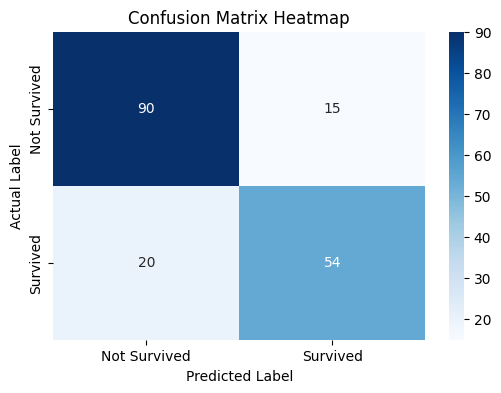

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
cm = confusion_matrix(y_test, rf_model_predictions)

# Plot heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Survived', 'Survived'],
            yticklabels=['Not Survived', 'Survived'])
plt.title('Confusion Matrix Heatmap')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

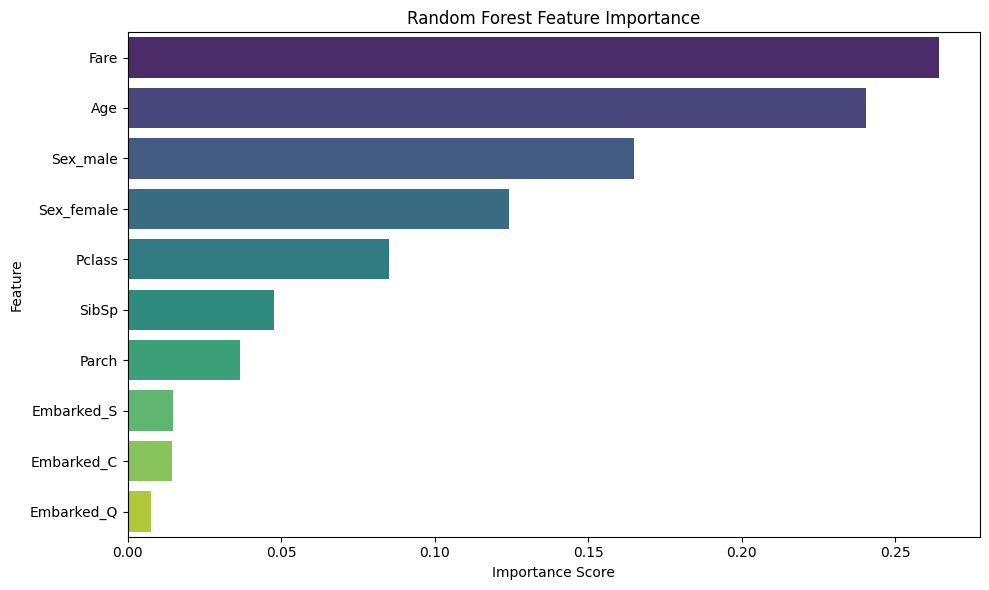

In [ ]:
# Get feature importances from the trained random forest model
importances = rf_model.feature_importances_
features = X.columns

# Create a DataFrame for easy sorting and plotting
feature_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis', hue='Feature', legend=False)
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression

# Initialize and train Logistic Regression model
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

# Calculate accuracies
rf_accuracy = rf_model.score(X_test_scaled, y_test)
lr_accuracy = lr_model.score(X_test_scaled, y_test)

print(f"Random Forest Accuracy:     {rf_accuracy:.4f}")
print(f"Logistic Regression Accuracy: {lr_accuracy:.4f}")

Random Forest Accuracy:     0.8045
Logistic Regression Accuracy: 0.8101


In [ ]:
from sklearn.model_selection import cross_val_score

# Scale the entire feature set X since cross-validation needs scaled inputs for Logistic Regression
X_scaled = scaler.fit_transform(X)

# Perform 5-Fold Cross-Validation for Random Forest
rf_cv_scores = cross_val_score(rf_model, X_scaled, y, cv=5)

# Perform 5-Fold Cross-Validation for Logistic Regression
lr_cv_scores = cross_val_score(lr_model, X_scaled, y, cv=5)

print("=== 5-Fold Cross-Validation Results ===")
print(f"Random Forest CV Mean Accuracy:     {rf_cv_scores.mean():.4f} (+/- {rf_cv_scores.std() * 2:.4f})")
print(f"Logistic Regression CV Mean Accuracy: {lr_cv_scores.mean():.4f} (+/- {lr_cv_scores.std() * 2:.4f})")

=== 5-Fold Cross-Validation Results ===
Random Forest CV Mean Accuracy:     0.8160 (+/- 0.0724)
Logistic Regression CV Mean Accuracy: 0.7857 (+/- 0.0368)


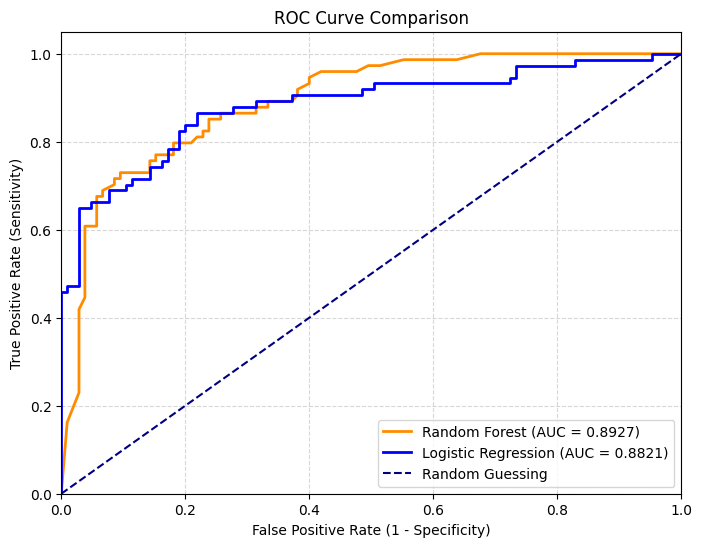

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# Get predicted probabilities for the positive class (Survived)
y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# Compute ROC curve and AUC score for Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_rf = roc_auc_score(y_test, y_prob_rf)

# Compute ROC curve and AUC score for Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
auc_lr = roc_auc_score(y_test, y_prob_lr)

# Plot the ROC curves
plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.4f})', color='darkorange', lw=2)
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.4f})', color='blue', lw=2)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--', label='Random Guessing')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid to search over
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Initialize GridSearchCV with 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Fit the grid search to the scaled training data
grid_search.fit(X_train_scaled, y_train)

# Print the best parameters and score found during training
print("Best Parameters Found:", grid_search.best_params_)
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best Parameters Found: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}
Best Cross-Validation Accuracy: 0.8314


In [ ]:
# Evaluate the tuned model on the test dataset
best_rf_model = grid_search.best_estimator_
tuned_accuracy = best_rf_model.score(X_test_scaled, y_test)

print(f"Original Random Forest Test Accuracy: {rf_accuracy:.4f}")
print(f"Tuned Random Forest Test Accuracy:    {tuned_accuracy:.4f}")

Original Random Forest Test Accuracy: 0.8045
Tuned Random Forest Test Accuracy:    0.8045


In [ ]:
# Align test_df_encoded to have the exact same features as the training set
# Retrieve the training feature names from X
training_features = X.columns.tolist()

# Handle binary categorical values correctly if they are boolean in test_df_encoded
for col in test_df_encoded.columns:
    if test_df_encoded[col].dtype == 'bool':
        test_df_encoded[col] = test_df_encoded[col].astype(int)

# Set PassengerId as index for alignment and drop unused columns
test_features = test_df_encoded.set_index('PassengerId')

# Ensure all columns present in training are present in test (filling missing columns with 0)
for col in training_features:
    if col not in test_features.columns:
        test_features[col] = 0

# Reorder columns to match the training set exactly
test_features = test_features[training_features]

# Scale the test features using the already fitted scaler
test_features_scaled = scaler.transform(test_features)

# Generate predictions using the best tuned Random Forest model
predictions = best_rf_model.predict(test_features_scaled)

# Create a submission DataFrame
submission_df = pd.DataFrame({
    'PassengerId': test_df_encoded['PassengerId'],
    'Survived': predictions
})

# Display the first few rows of the submission
display(submission_df.head())

# Save the predictions to a CSV file
submission_df.to_csv('submission.csv', index=False)
print("Predictions generated and saved to 'submission.csv'")

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


Predictions generated and saved to 'submission.csv'
